In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors

import statsmodels.api as sm
from analysis import *

In [2]:
sim_scenario = 'full_pipeline'

def logistic_model(df, dep_var, scenario, duplicate):
    df2 = df.query('scenario == @scenario and duplicate == @duplicate').copy()

    # Fit logistic regression
    X = sm.add_constant(df2[dep_var])
    y = df2['pass_null']
    model = sm.Logit(y, X).fit(disp=False)
    return model, df2

dep_var = 'n_transient'
model, df2 = logistic_model(df, dep_var, sim_scenario, 0)

last_time = model.params[dep_var]
p = model.pvalues[dep_var]
print(f'The coefficient of {dep_var} is {last_time:.3f} with p={p:.2e}.')

model.summary()

The coefficient of n_transient is 0.170 with p=5.77e-03.


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              pass_null   No. Observations:                  277
Model:                          Logit   Df Residuals:                      275
Method:                           MLE   Df Model:                            1
Date:                Thu, 04 Jun 2026   Pseudo R-squ.:                 0.04703
Time:                        08:32:23   Log-Likelihood:                -94.478
converged:                       True   LL-Null:                       -99.141
Covariance Type:            nonrobust   LLR p-value:                  0.002260
===============================================================================
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.9707      0.388      2.504      0.012       0.211       1.731
n_transient     0.1696      0.061      2.760      0.006       0.049       0.290
===============================================================================
"""

In [3]:
def darken(hex_color, amount=0.2):
    """
    Darken a hex color by blending toward black.
    """
    rgb = np.array(mcolors.to_rgb(hex_color))
    darker = (1 - amount) * rgb
    return mcolors.to_hex(darker)

inv_logit = lambda x: 1 / (1 + np.exp(-x))

In [4]:
def panel(ax, df, scenario, label, duplicate, color):
    model, df2 = logistic_model(df, dep_var, scenario, duplicate)
    
    last_time = model.params[dep_var]
    p = model.pvalues[dep_var]
    
    # Generate a grid of last_time values across the observed range
    x = np.linspace(0, 17, 100)
    x_pred = sm.add_constant(x)
    y_pred = 100 * model.predict(x_pred)
    
    # Confidence inteervals
    cov = model.cov_params()
    params = model.params.values
    
    # Linear predictor and its variance
    lin_pred = x_pred @ params
    var_lin_pred = np.sum((x_pred @ cov) * x_pred, axis=1)
    se_lin_pred = np.sqrt(var_lin_pred)
    
    # 95% CI on logit scale, then transform back to probability
    logit_lower = lin_pred - 1.96 * se_lin_pred
    logit_upper = lin_pred + 1.96 * se_lin_pred
    
    ci_lower = 100 * inv_logit(logit_lower)
    ci_upper = 100 * inv_logit(logit_upper)
    
    agg = df2.groupby(['fish']).agg({'pass_null': 'mean', dep_var: 'first', 'clone': 'count'})
    agg['pass_null'] = agg['pass_null'] * 100
    
    rng = np.random.default_rng()
    x_jittered = agg[dep_var] + rng.uniform(-0.25, 0.25, size=len(agg))
    ax.scatter(x_jittered, agg['pass_null'], color = color,
        edgecolors='black', linewidths=0.5, zorder=5,
        s = agg['clone'], alpha = 0.7
    )
    
    ax.plot(x, y_pred, color=darken(color), linewidth=2, label="Logit fit")
    
    # Confidence interval band
    ax.fill_between(x, ci_lower, ci_upper, color=color, alpha=0.3, label="95% CI")
    ax.set_xlabel('# samples collected', fontweight = 'bold')
    
    ax.set_ylim(0, 105)
    ax.set_xlim(0, 18)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_xticks([0, 5, 10, 15])

    a = f"{p:.2e}".split("e")[0]          # mantissa
    b = int(f"{p:.2e}".split("e")[1])     # exponent
    ax.text(16, 5, rf"$p = {a} \times 10^{{{b}}}$", fontsize=6,
        ha='right', va='bottom'
    )
    ax.set_title(label, fontweight = 'bold')

    ax.grid(True, linestyle=':', linewidth=0.8, color='lightgray', axis = 'y')

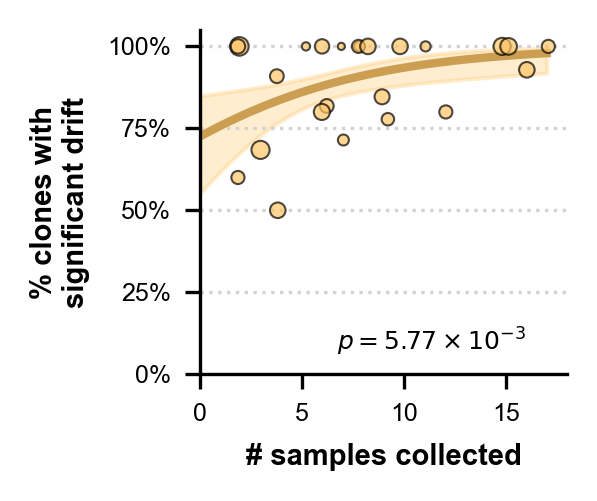

In [5]:
plt.rcParams.update(small_label_settings)
fig, ax = plt.subplots(figsize = (2, 1.68), dpi = 300)

label = None
panel(ax, df, 'full_pipeline', label, 0, exp_hue)
ax.set_ylabel('% clones with\nsignificant drift', fontweight = 'bold')

# sizes = [3, 19]
# legend_handles = [
#     plt.scatter([], [], s=size, color='#ffc566',
#                 edgecolors='black', linewidths=0.5)
#     for size in sizes
# ]

# leg = ax.legend(legend_handles, [f"{size} clones" for size in sizes],
#     frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0),
#     ncol=1, fontsize=6, handletextpad=0.2
# )


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

filepath = os.path.join('images', 'fig3', 'drift_vs_samples')
plt.savefig(f'{filepath}.svg', bbox_inches = 'tight', pad_inches = 0)
plt.savefig(f'{filepath}.png', dpi = 300, bbox_inches = 'tight', pad_inches = 0)

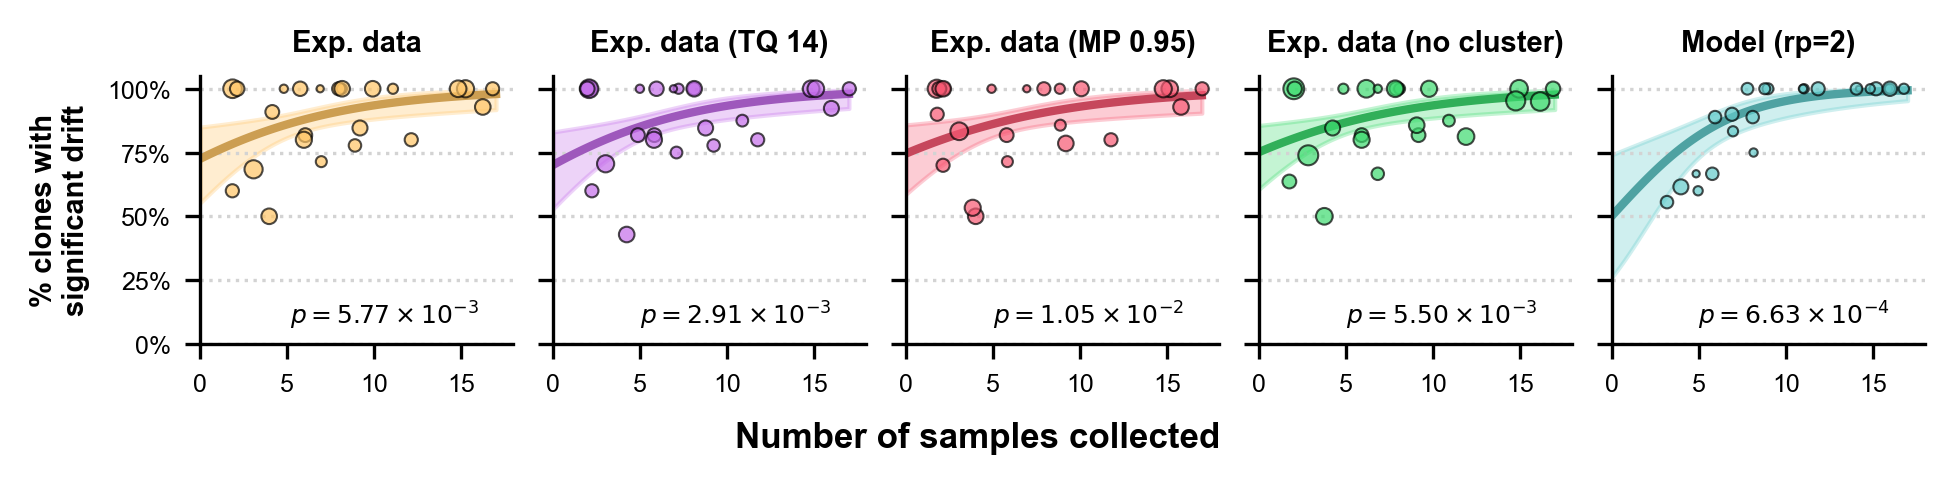

In [7]:
fig, ax = plt.subplots(1, 5, figsize = (6.4, 1.5), dpi = 300, sharey = True, constrained_layout = True)

scenarios = ['full_pipeline', 'full_pipeline_TQ14', 'full_pipeline_MP0.95', 'no_cluster', 'r36_rp2_mimic']
scenarios_labels = ['Exp. data', 'Exp. data (TQ 14)', 'Exp. data (MP 0.95)', 'Exp. data (no cluster)', 'Model (rp=2)']
colors = [exp_hue, tq_hue, mp_hue, no_collapse_hue, hue(2)]

for i, (scenario, label, color) in enumerate(zip(scenarios, scenarios_labels, colors)):
    panel(ax[i], df, scenario, label, 0, color)
    ax[i].set_xlabel('')
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)
    
ax[0].set_ylabel('% clones with\nsignificant drift', fontweight = 'bold')
fig.supxlabel('Number of samples collected', fontweight = 'bold')

filepath = os.path.join('images', 'fig3', 'drift_vs_samples_supplement')
plt.savefig(f'{filepath}.svg', bbox_inches = 'tight', pad_inches = 0)
plt.savefig(f'{filepath}.png', dpi = 300, bbox_inches = 'tight', pad_inches = 0)

In [7]:
# Re-run the statistical test on additional simulation runs
sim_scenario = 'r36_rp2_mimic'

rows = []
for d in df[df['scenario'] == sim_scenario]['duplicate'].unique():
    model, df2 = logistic_model(df, dep_var, sim_scenario, d)
    
    last_time = model.params[dep_var]
    p = model.pvalues[dep_var]

    row = {'Duplicate': d, 'coef': last_time, 'p': p}
    rows.append(row)

results_df = pd.DataFrame(rows)
results_df

,Duplicate,coef,p
0,0,0.298350,0.000663
1,1,0.498285,0.000575
2,2,0.312203,0.000721
3,3,0.407182,0.000076
4,4,0.324243,0.000516
5,5,0.261893,0.002878
6,6,0.364512,0.002493
7,7,0.318144,0.000412
8,8,0.495005,0.000044
9,9,0.417032,0.000491
